# Actividad 5 · Preparación de datos, entrenamiento y registro de experimentos con MLflow

**Materia:** Gestión de proyectos de inteligencia artificial · Universidad Tecmilenio
**Alumno:** Brandon Gilberto Imanol Retana Fuentes

**Problema.** Clasificar vinos *vinho verde* (tintos y blancos) como **calidad alta** (puntaje sensorial ≥ 7) a partir de 11 variables fisicoquímicas de laboratorio. Un modelo así permitiría a una bodega priorizar qué lotes enviar al panel sensorial o a una línea premium.

**Flujo del notebook**

| Paso | Qué se hace | Código |
|---|---|---|
| 1 | Obtención y verificación de integridad (SHA-256) | `fuentes/obtener_datos.py` |
| 2 | Limpieza, estandarización, reglas de negocio y versionamiento | `fuentes/datos_prep.py` |
| 3 | Visualizaciones de calidad de datos (patrones y anomalías) | `fuentes/visualizaciones.py` |
| 4 | Entrenamiento de 3 modelos + línea base con `GridSearchCV` y registro en MLflow | `fuentes/train.py` |
| 5 | Comparación estadística y selección del modelo campeón | `fuentes/train.py` |
| 6 | Trazabilidad: consulta de runs y recarga del modelo registrado | MLflow API |

> En Google Colab: *Entorno de ejecución → Ejecutar todo*. La primera celda clona el repositorio e instala dependencias. Tiempo aproximado: 10–15 min en CPU.

In [1]:
# 0. Configuración del entorno (local o Google Colab)
import os, sys, subprocess
from pathlib import Path

EN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/BGIRF/BGIRF_Actividad_5_GPIA.git"

if EN_COLAB:
    if not Path("/content/Actividad5").exists():
        subprocess.run(["git", "clone", REPO_URL, "/content/Actividad5"], check=True)
    os.chdir("/content/Actividad5")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "mlflow>=3.0", "xgboost", "statsmodels", "skops"], check=True)

RAIZ = Path.cwd() if (Path.cwd() / "fuentes").exists() else Path.cwd().parent
os.chdir(RAIZ)
sys.path.insert(0, str(RAIZ / "fuentes"))
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"

import warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, sklearn, xgboost, mlflow, platform
from IPython.display import Image, display
pd.set_option("display.precision", 4)
pd.set_option("display.max_columns", 30)

print(f"Raíz del proyecto: {RAIZ}")
print(f"Python {platform.python_version()} · scikit-learn {sklearn.__version__} · xgboost {xgboost.__version__} · mlflow {mlflow.__version__}")

Raíz del proyecto: /home/claude/Actividad5
Python 3.13.16 · scikit-learn 1.9.1 · xgboost 3.4.1 · mlflow 3.17.1


## 1. Obtención y verificación del dataset

**Fuente:** *Wine Quality* (Cortez et al., 2009), UCI Machine Learning Repository (id 186), licencia CC BY 4.0. Dos archivos originales: tintos (1,599 registros) y blancos (4,898). Los archivos se versionan en `datos/datos_ini/` y su integridad se valida con SHA-256 antes de cualquier procesamiento: si alguien modifica un byte del dato original, el pipeline se detiene.

In [2]:
from obtener_datos import verificar_datos
huellas = verificar_datos()
pd.DataFrame(huellas).T

  OK  winequality-red.csv  sha256=4a402cf041b025d4...
  OK  winequality-white.csv  sha256=76c3f809815c17c0...


,ruta,sha256
winequality-red.csv,datos/datos_ini/winequality-red.csv,4a402cf041b025d4566d954c3b9ba8635a3a8a01e03900...
winequality-white.csv,datos/datos_ini/winequality-white.csv,76c3f809815c17c07212622f776311faeb31e87610d52c...


## 2. Limpieza, estandarización y versionamiento

`datos_prep.ejecutar_pipeline()` aplica, en orden: unión tinto + blanco con un `id_registro` de linaje (R0001…, W0001…), nombres en *snake_case*, tipos explícitos, manejo de nulos, eliminación de duplicados exactos, reglas de negocio, marcado de atípicos y creación de la variable objetivo. El resultado se guarda como **versión 1.1.0** en `datos/datos_limp/` y su huella queda en `datos/MANIFEST.json`.

El **escalado** y la **codificación** de `tipo` se aplican dentro del `Pipeline` de scikit-learn en el paso 4 (ajustados solo con entrenamiento) para no filtrar información de validación o prueba.

In [3]:
import datos_prep as dp
df, reporte = dp.ejecutar_pipeline()
display(dp.diccionario_de_datos())

  OK  winequality-red.csv  sha256=4a402cf041b025d4...
  OK  winequality-white.csv  sha256=76c3f809815c17c0...


Filas originales: 6497  ->  finales: 5320
Duplicados eliminados: 1177 {'blanco': 937, 'tinto': 240}
Filas eliminadas por reglas de validez: 0
Marcadas SO2 > límite UE: 63 {'blanco': 56, 'tinto': 7}
Registros con algún atípico extremo: 302
Prevalencia calidad alta: 19.0%


,variable,nombre_original,unidad,descripcion
0,tipo,(archivo de origen),categoría,tinto / blanco
1,acidez_fija,fixed acidity,g ácido tartárico/L,"Ácidos no volátiles (tartárico, málico)"
2,acidez_volatil,volatile acidity,g ácido acético/L,Ácido acético; en exceso da sabor a vinagre
3,acido_citrico,citric acid,g/L,Aporta frescura; en baja proporción
4,azucar_residual,residual sugar,g/L,Azúcar remanente tras la fermentación
5,cloruros,chlorides,g cloruro de sodio/L,Contenido de sal
6,so2_libre,free sulfur dioxide,mg/L,SO2 libre (antimicrobiano/antioxidante)
7,so2_total,total sulfur dioxide,mg/L,SO2 libre + combinado
8,densidad,density,g/cm³,Depende de alcohol y azúcar
9,ph,pH,-,Acidez (escala 0-14)


In [4]:
resumen_limpieza = pd.DataFrame([
    ("Registros originales", reporte["filas_originales"]),
    ("Valores no numéricos convertidos a NaN", sum(reporte["valores_no_numericos"].values())),
    ("Valores nulos (todas las columnas)", sum(reporte["nulos"]["nulos_por_columna"].values())),
    ("Duplicados exactos eliminados", reporte["duplicados"]["duplicados_eliminados"]),
    ("  · tintos / blancos", f"{reporte['duplicados']['duplicados_por_tipo']['tinto']} / {reporte['duplicados']['duplicados_por_tipo']['blanco']}"),
    ("Duplicados con etiqueta en conflicto", reporte["duplicados"]["etiquetas_en_conflicto"]),
    ("Filas eliminadas por reglas de validez (R1–R4)", reporte["reglas_negocio"]["filas_eliminadas_por_reglas"]),
    ("Marcadas: SO₂ total > límite UE (R5)", reporte["reglas_negocio"]["R5_excede_so2_ue_marcadas"]),
    ("Registros con ≥1 atípico extremo (3·IQR)", reporte["atipicos"]["registros_con_algun_atipico"]),
    ("Registros finales (v1.1.0)", reporte["filas_finales"]),
    ("Prevalencia de calidad alta", f"{reporte['prevalencia_calidad_alta']:.1%}"),
], columns=["Concepto", "Valor"])
display(resumen_limpieza)
print("SHA-256 dataset limpio:", reporte["sha256_limpio"])

,Concepto,Valor
0,Registros originales,6497
1,Valores no numéricos convertidos a NaN,0
2,Valores nulos (todas las columnas),0
3,Duplicados exactos eliminados,1177
4,· tintos / blancos,240 / 937
5,Duplicados con etiqueta en conflicto,0
6,Filas eliminadas por reglas de validez (R1–R4),0
7,Marcadas: SO₂ total > límite UE (R5),63
8,Registros con ≥1 atípico extremo (3·IQR),302
9,Registros finales (v1.1.0),5320


SHA-256 dataset limpio: c40859031f721635fe8eb99ef2f48652b2fb46d7591f17d53d211c81376b2234


**Decisiones de limpieza**

* **Duplicados (1,177; 18 % del total).** Se eliminan las coincidencias exactas en tipo + 11 variables + calidad, conservando la primera aparición. Ninguno tiene etiquetas en conflicto. Mantenerlos haría que el mismo vino apareciera en entrenamiento y validación a la vez, inflando las métricas.
* **Nulos y tipos.** El dataset no trae nulos ni valores no numéricos; aun así el pipeline los controla (filas sin objetivo se eliminan; nulos en variables se imputan con la mediana dentro del modelo).
* **Reglas de negocio.** R1–R4 (concentraciones no negativas, SO₂ libre ≤ total, rangos plausibles de pH, densidad y alcohol, calidad 0–10) no eliminaron filas: quedan como validaciones automáticas para versiones futuras del dato. R5 marca 63 vinos con SO₂ total por encima del límite del Reglamento (UE) 2019/934; se conservan porque el objetivo es la calidad sensorial, no la conformidad regulatoria.
* **Atípicos.** Se marcan (no se eliminan) los valores extremos por tipo de vino: son vinos reales, los árboles son robustos y para la regresión logística se evalúa una transformación Yeo-Johnson dentro del *grid*.

## 3. Visualizaciones de calidad de datos

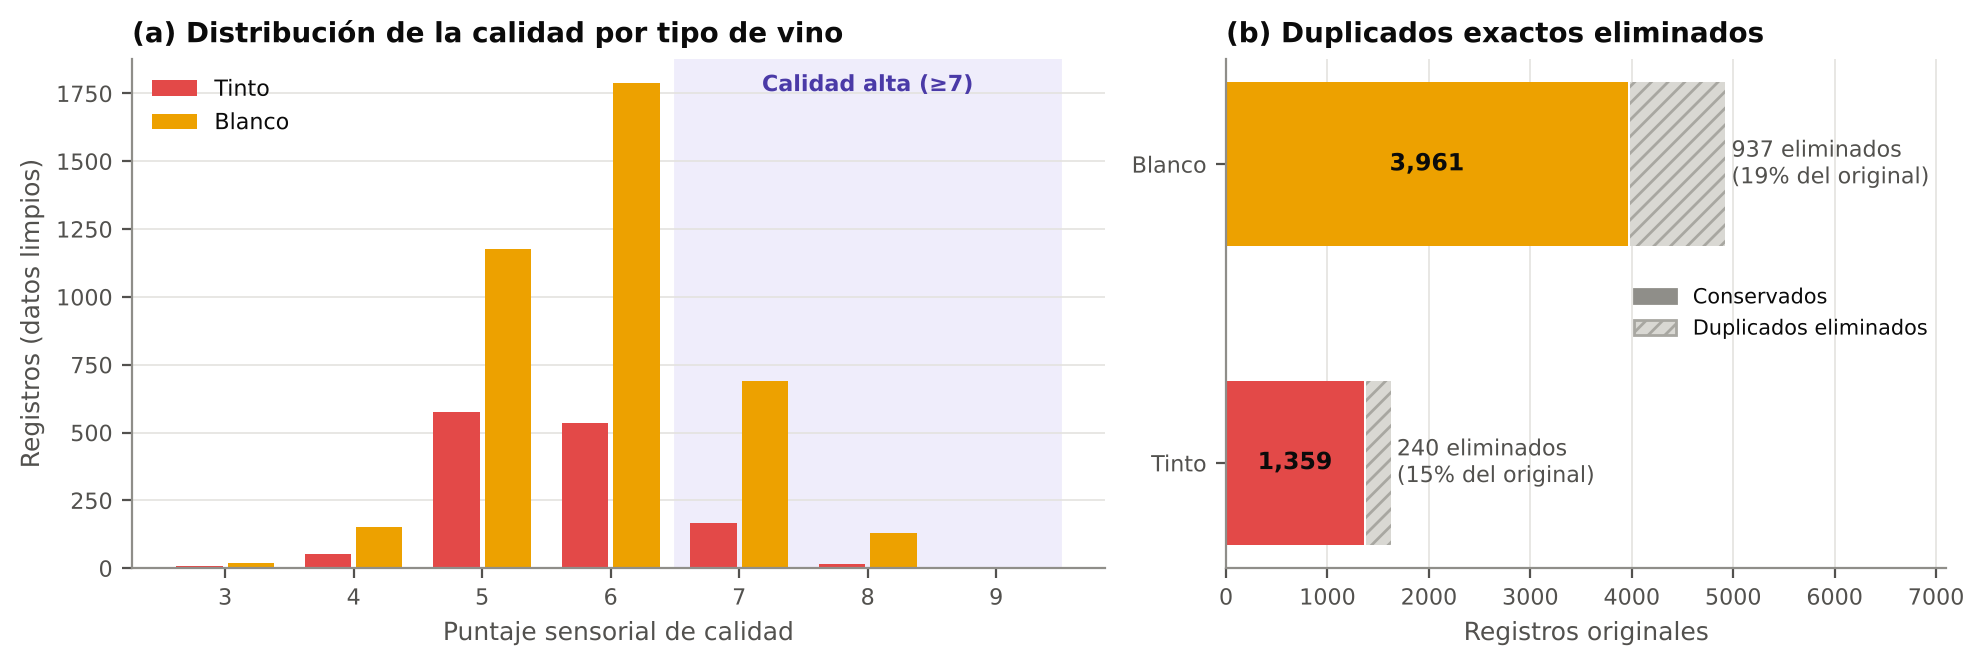

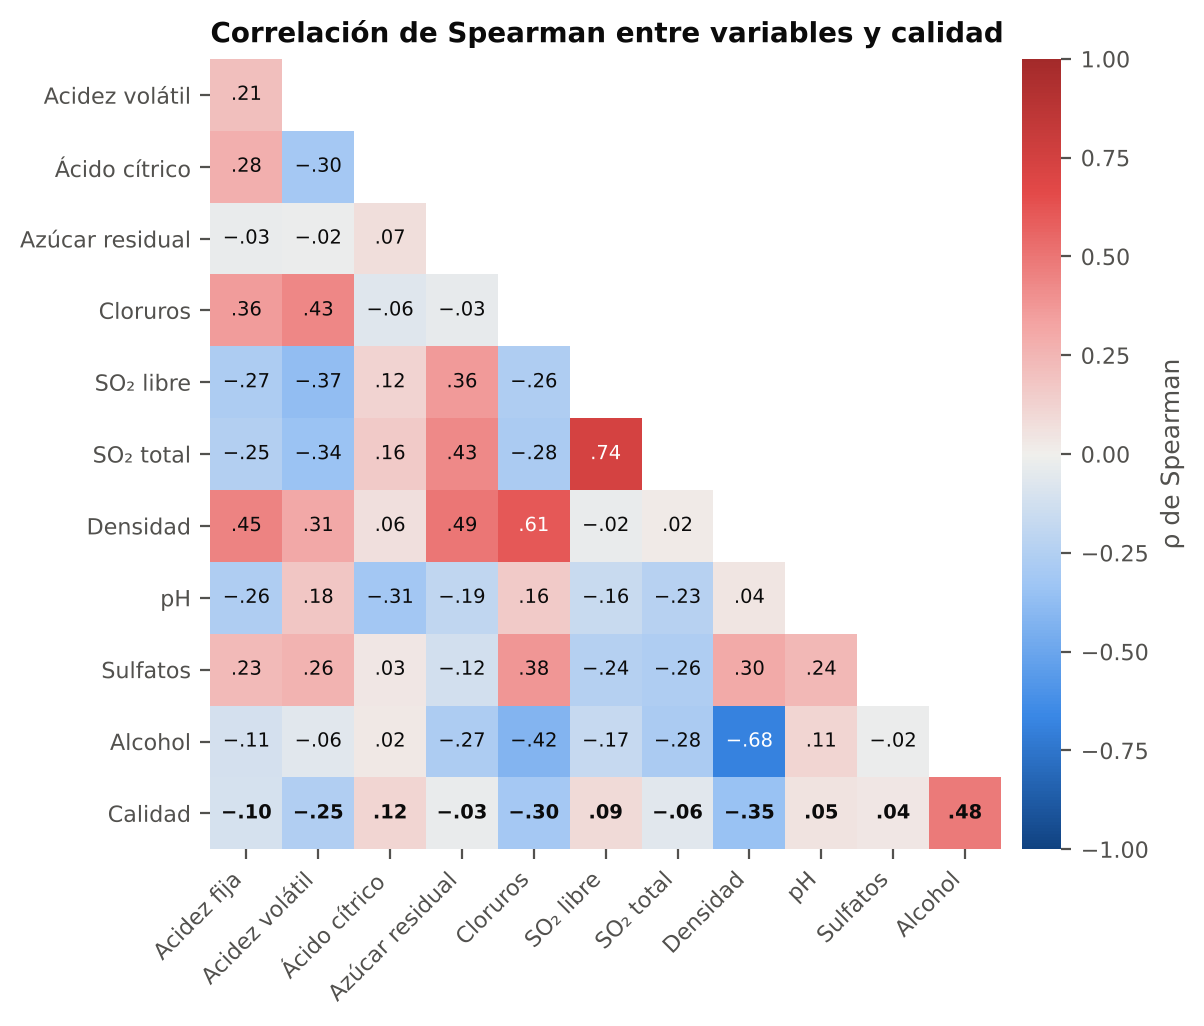

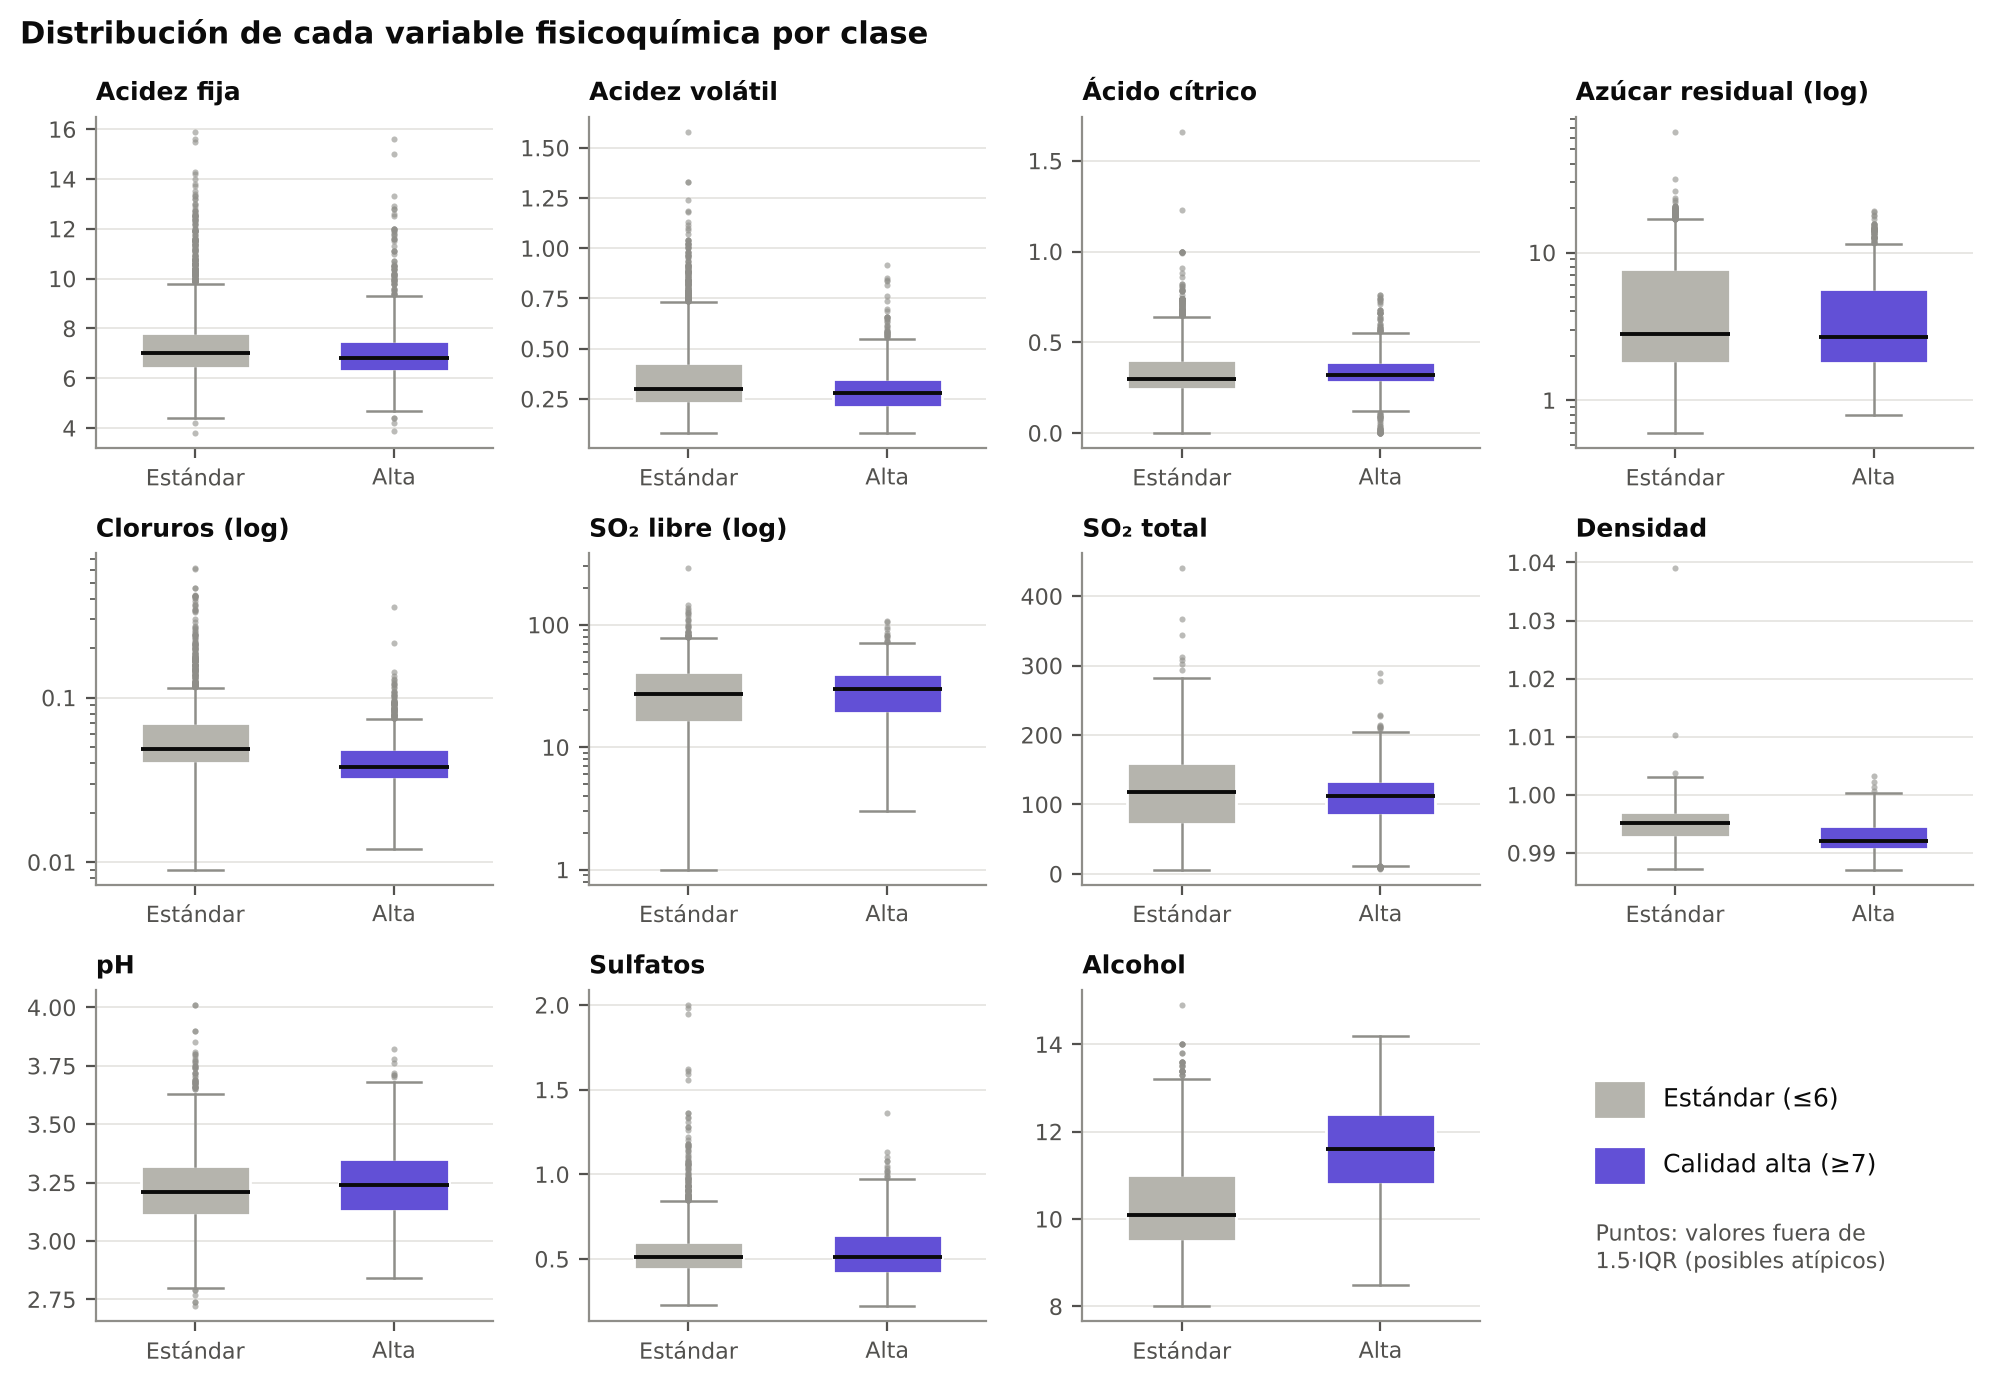

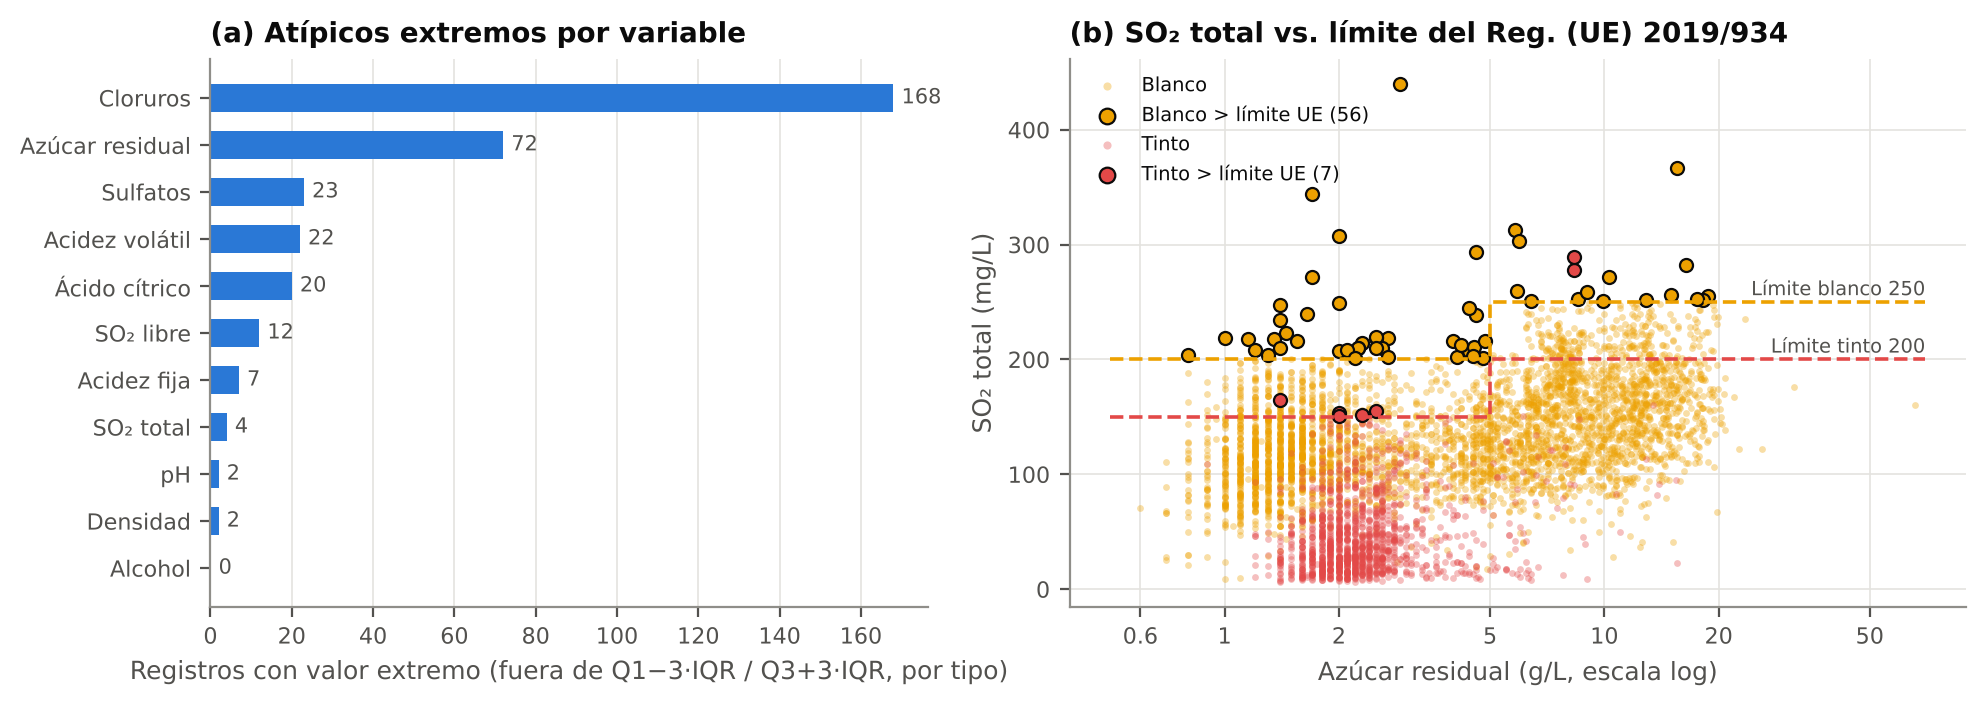

In [5]:
import visualizaciones as viz
for f in [viz.fig_calidad_y_duplicados(df, reporte), viz.fig_correlaciones(df),
          viz.fig_distribuciones_por_clase(df), viz.fig_atipicos_y_regulatorio(df, reporte)]:
    display(Image(filename=str(f), width=900))

**Lectura de las gráficas**

* **Desbalance de clases:** la calidad se concentra en 5 y 6; solo 19 % de los vinos es de calidad alta (13.5 % en tintos, 20.8 % en blancos). Por eso la *accuracy* no basta: un clasificador que siempre dice "estándar" ya obtiene 81 %. Se usan ROC-AUC, PR-AUC, F1, precisión y recall, y particiones estratificadas por clase y tipo.
* **Patrones:** el alcohol es la variable más asociada con la calidad (ρ = 0.48); densidad (−0.35), cloruros (−0.30) y acidez volátil (−0.25) se asocian negativamente. Densidad y alcohol están muy correlacionados (−0.68), y SO₂ libre y total también (0.74): hay redundancia que afecta más a la regresión logística (coeficientes inestables) que a los árboles.
* **Anomalías:** cloruros y azúcar residual concentran los atípicos extremos (vinos blancos dulces, un registro con 65.8 g/L de azúcar y densidad 1.039). 63 vinos exceden el límite regulatorio de SO₂ total (la mayoría, 41, son blancos secos con más de 200 mg/L) y solo 3 de ellos (4.8 %) son de calidad alta, frente al 19 % general: el exceso de SO₂ coincide con peor calidad sensorial.

## 4. Entrenamiento, ajuste de hiperparámetros y registro en MLflow

`train.main()` ejecuta todo el experimento y lo registra en MLflow (`sqlite:///mlflow.db`, artefactos en `mlruns/`):

* **Partición:** 80 % entrenamiento / 20 % prueba, estratificada por clase y tipo, semilla 42 (`salidas/metricas/particion_train_test.csv`).
* **Validación cruzada:** `StratifiedKFold(k=5)`; `GridSearchCV` multi-métrica con *refit* por ROC-AUC (métrica independiente del umbral y robusta al desbalance).
* **Umbral de decisión:** el que maximiza F1 en predicciones *out-of-fold* del entrenamiento (la prueba no se toca para decidir nada).
* **MLflow:** un run padre por modelo (mejores hiperparámetros, métricas de CV y prueba, dataset de entrada, artefactos, modelo con firma) y un run hijo por cada combinación de la rejilla; al final, un run de comparación estadística y el registro del campeón en el *Model Registry* con alias `champion`.

In [6]:
import train
salida = train.main()

2026/10/18 20:18:14 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/10/18 20:18:14 INFO mlflow.store.db.utils: Updating database tables


MLflow tracking URI: sqlite:////home/claude/Actividad5/mlflow.db
Experimento: Actividad5_WineQuality_CalidadAlta
Entrenamiento: 4256 (19.0% positivos) · Prueba: 1064 (19.0% positivos)



[00] Línea base: accuracy prueba=0.810 · F1=0.000 · ROC-AUC=0.500

[01] Regresión logística: GridSearchCV con 20 combinaciones x 5 pliegues


     mejor CV ROC-AUC=0.8250 · prueba ROC-AUC=0.8462 F1=0.5704 (umbral 0.22) · 11s

[02] Random Forest: GridSearchCV con 36 combinaciones x 5 pliegues


     mejor CV ROC-AUC=0.8541 · prueba ROC-AUC=0.8676 F1=0.5880 (umbral 0.36) · 198s

[03] XGBoost: GridSearchCV con 48 combinaciones x 5 pliegues


     mejor CV ROC-AUC=0.8479 · prueba ROC-AUC=0.8706 F1=0.6008 (umbral 0.24) · 37s

[04] Comparación estadística y selección del modelo campeón


Successfully registered model 'wine_calidad_alta_clf'.
Created version '1' of model 'wine_calidad_alta_clf'.


     Campeón: Random Forest -> models:/wine_calidad_alta_clf@champion (v1); recarga reproduce predicciones: True
     Friedman χ²=28.13, p=0.0000

Resumen de métricas en prueba:
                     accuracy  precision  recall     f1  roc_auc  pr_auc  balanced_accuracy  especificidad  umbral
Línea base (Dummy)      0.810      0.000   0.000  0.000    0.500   0.190              0.500          1.000   0.500
Regresión logística     0.779      0.452   0.772  0.570    0.846   0.557              0.777          0.781   0.220
Random Forest           0.800      0.483   0.752  0.588    0.868   0.612              0.782          0.811   0.360
XGBoost                 0.814      0.507   0.738  0.601    0.871   0.619              0.785          0.832   0.245


## 5. Resultados y comparación estadística

In [7]:
comp = salida["comparacion"]
print("Validación cruzada (GridSearch 5-fold y CV repetida 5×3):")
display(comp["tabla_cv"][["roc_auc", "roc_auc_desv", "pr_auc", "f1", "train_roc_auc", "auc_cv_repetida_media", "auc_cv_repetida_desv"]].round(4))
print("Conjunto de prueba (umbral optimizado por F1 en OOF):")
display(comp["tabla_prueba"].round(4))

Validación cruzada (GridSearch 5-fold y CV repetida 5×3):


,roc_auc,roc_auc_desv,pr_auc,f1,train_roc_auc,auc_cv_repetida_media,auc_cv_repetida_desv
Línea base (Dummy),0.5000,NaN,0.1896,0.0000,NaN,NaN,NaN
Regresión logística,0.8250,0.0170,0.5061,0.3698,0.8278,0.8249,0.0168
Random Forest,0.8541,0.0172,0.5758,0.5378,0.9983,0.8513,0.0124
XGBoost,0.8479,0.0149,0.5559,0.4721,0.9990,0.8459,0.0123


Conjunto de prueba (umbral optimizado por F1 en OOF):


,accuracy,precision,recall,f1,roc_auc,pr_auc,balanced_accuracy,especificidad,umbral
Línea base (Dummy),0.8102,0.0000,0.0000,0.0000,0.5000,0.1898,0.5000,1.0000,0.5000
Regresión logística,0.7791,0.4522,0.7723,0.5704,0.8462,0.5573,0.7765,0.7807,0.2204
Random Forest,0.7998,0.4825,0.7525,0.5880,0.8676,0.6120,0.7817,0.8109,0.3597
XGBoost,0.8139,0.5068,0.7376,0.6008,0.8706,0.6192,0.7847,0.8318,0.2445


In [8]:
print("Mejores hiperparámetros:")
display(pd.DataFrame({r["nombre"]: r.get("mejores_params") for r in salida["resultados"].values() if "mejores_params" in r}).T
          .map(lambda v: type(v).__name__ if hasattr(v, "fit") else v))
f_stat, f_p = comp["friedman"]
print(f"Friedman (ROC-AUC, 15 pliegues pareados): chi2 = {f_stat:.2f}, p = {f_p:.2e}")
print("\nPruebas por pares en CV repetida (p ajustados por Holm):")
display(comp["pruebas_cv"].round(4))
print("Pruebas por pares en el conjunto de prueba (McNemar exacto + IC 95 % bootstrap de la diferencia de AUC):")
display(comp["pruebas_prueba"].round(4))

Mejores hiperparámetros:


,clf__C,clf__class_weight,prep__num__escalar,clf__max_depth,clf__max_features,clf__min_samples_leaf,clf__learning_rate,clf__n_estimators,clf__scale_pos_weight,clf__subsample
Regresión logística,1.0,NaN,StandardScaler,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Random Forest,NaN,balanced_subsample,NaN,20.0,sqrt,3.0,NaN,NaN,NaN,NaN
XGBoost,NaN,NaN,NaN,7.0,NaN,NaN,0.05,200.0,1.0,0.8


Friedman (ROC-AUC, 15 pliegues pareados): chi2 = 28.13, p = 7.78e-07

Pruebas por pares en CV repetida (p ajustados por Holm):


,modelo_a,modelo_b,dif_media_auc,pliegues_a_gana,t_corregida,p_t_corregida,wilcoxon_W,p_wilcoxon,p_t_holm,p_wilcoxon_holm
0,Regresión logística,Random Forest,-0.0264,0,-4.2239,0.0009,0.0,0.0001,0.0026,0.0002
1,Regresión logística,XGBoost,-0.0210,0,-3.9709,0.0014,0.0,0.0007,0.0028,0.0007
2,Random Forest,XGBoost,0.0054,14,2.0603,0.0585,1.0,0.0001,0.0585,0.0002


Pruebas por pares en el conjunto de prueba (McNemar exacto + IC 95 % bootstrap de la diferencia de AUC):


,modelo_a,modelo_b,a_acierta_b_falla,a_falla_b_acierta,p_mcnemar,dif_auc_prueba,ic95_dif_auc_inf,ic95_dif_auc_sup
0,Regresión logística,Random Forest,47,69,0.0507,-0.0214,-0.0407,-0.0028
1,Regresión logística,XGBoost,42,79,0.0010,-0.0244,-0.0442,-0.0054
2,Random Forest,XGBoost,23,38,0.0722,-0.0031,-0.0113,0.0053


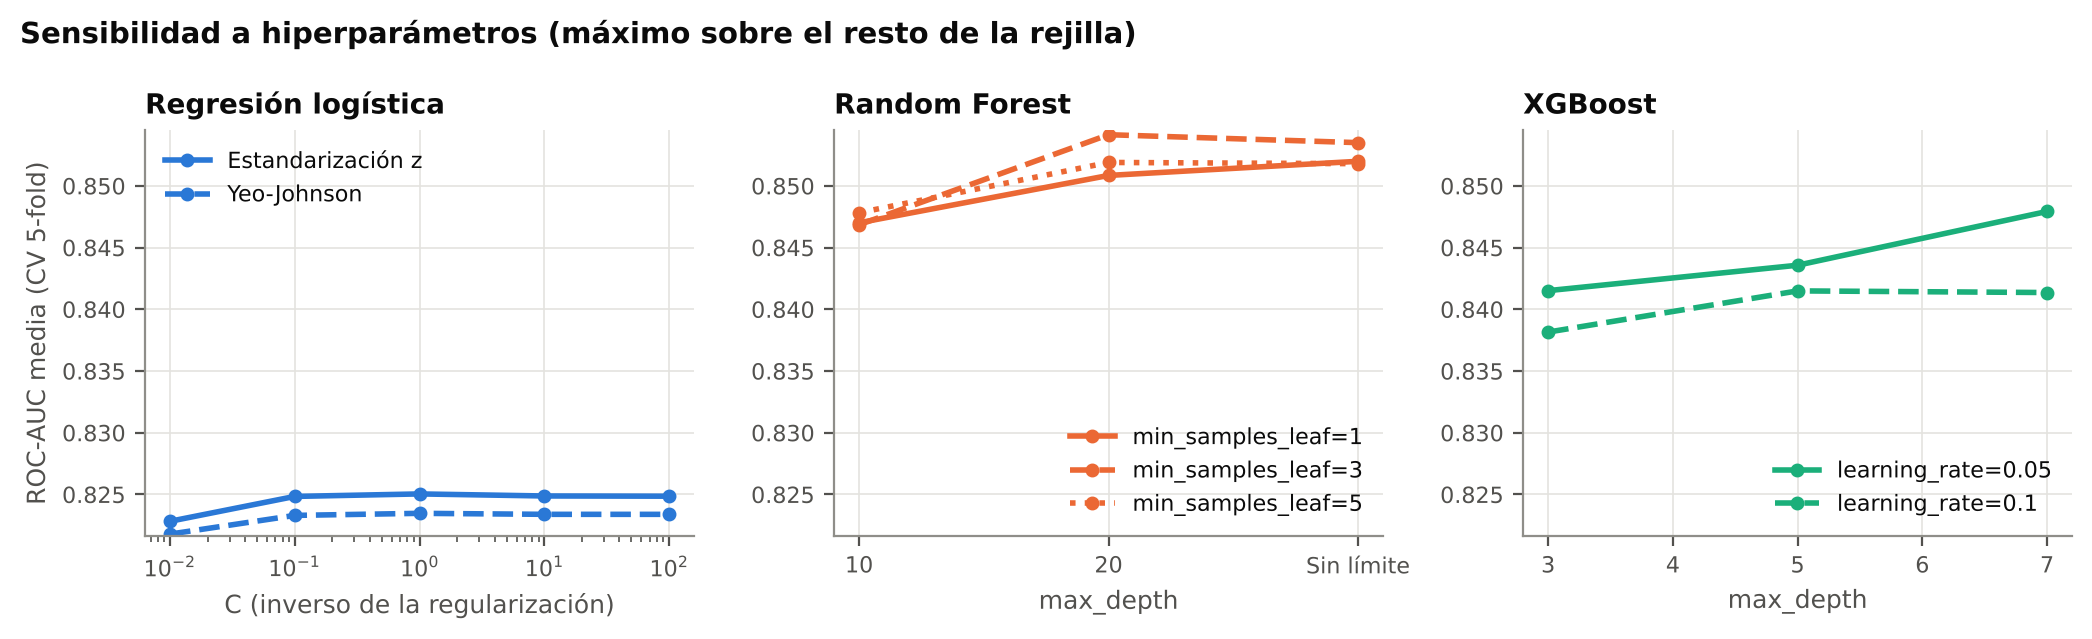

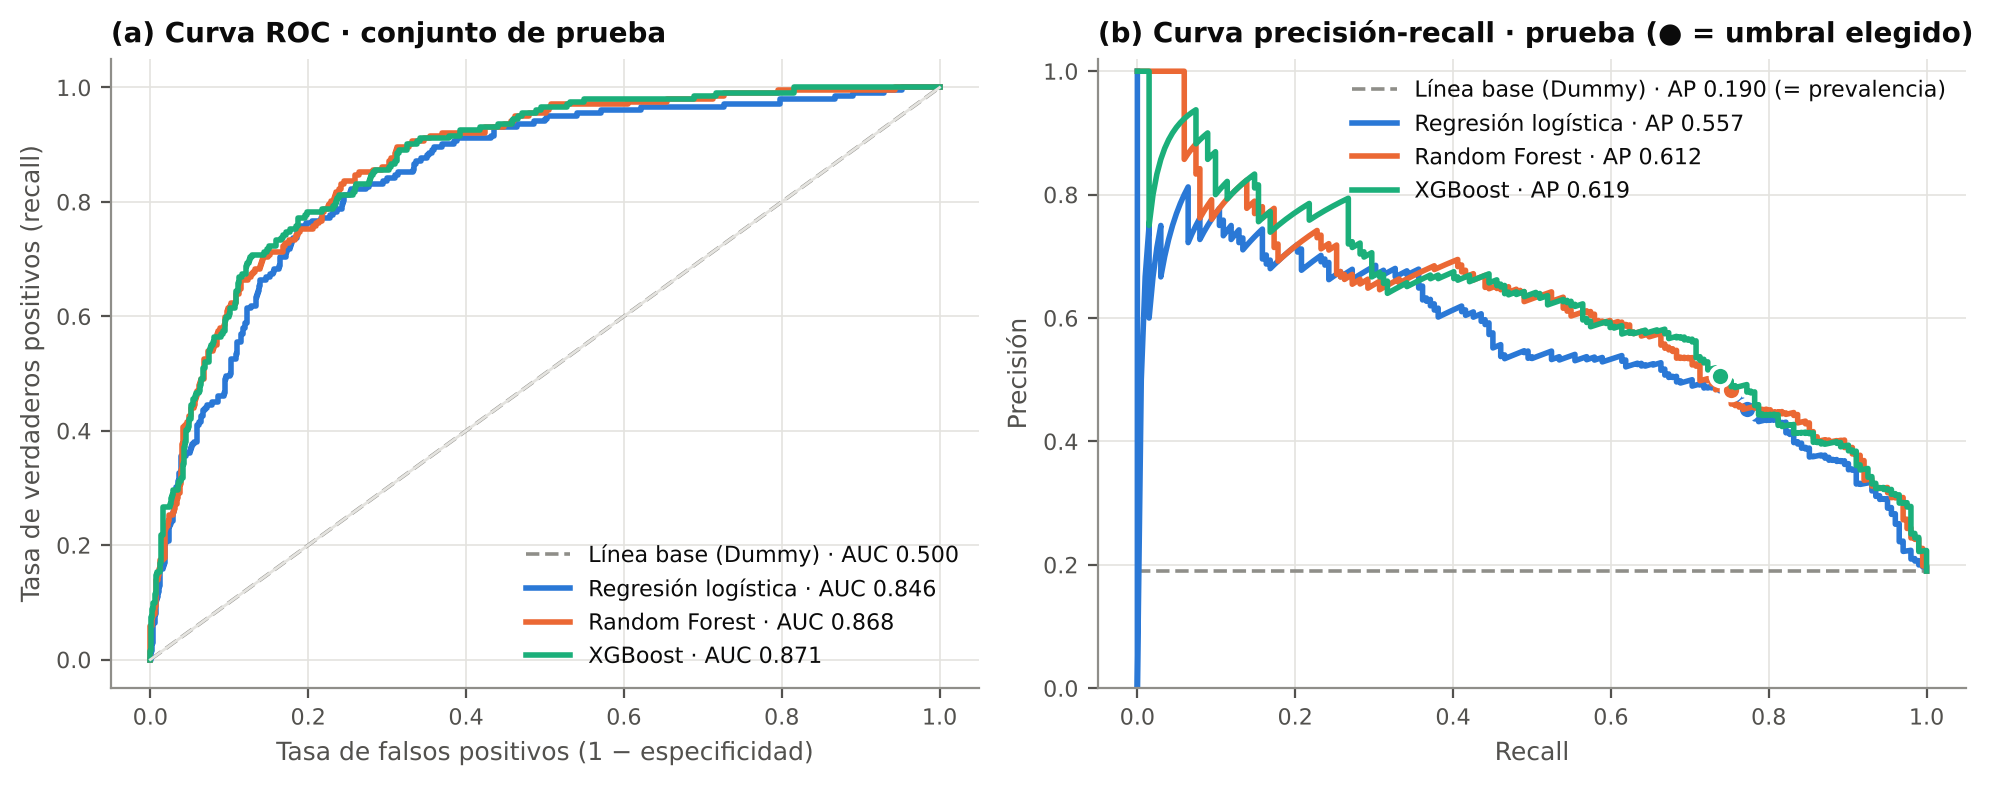

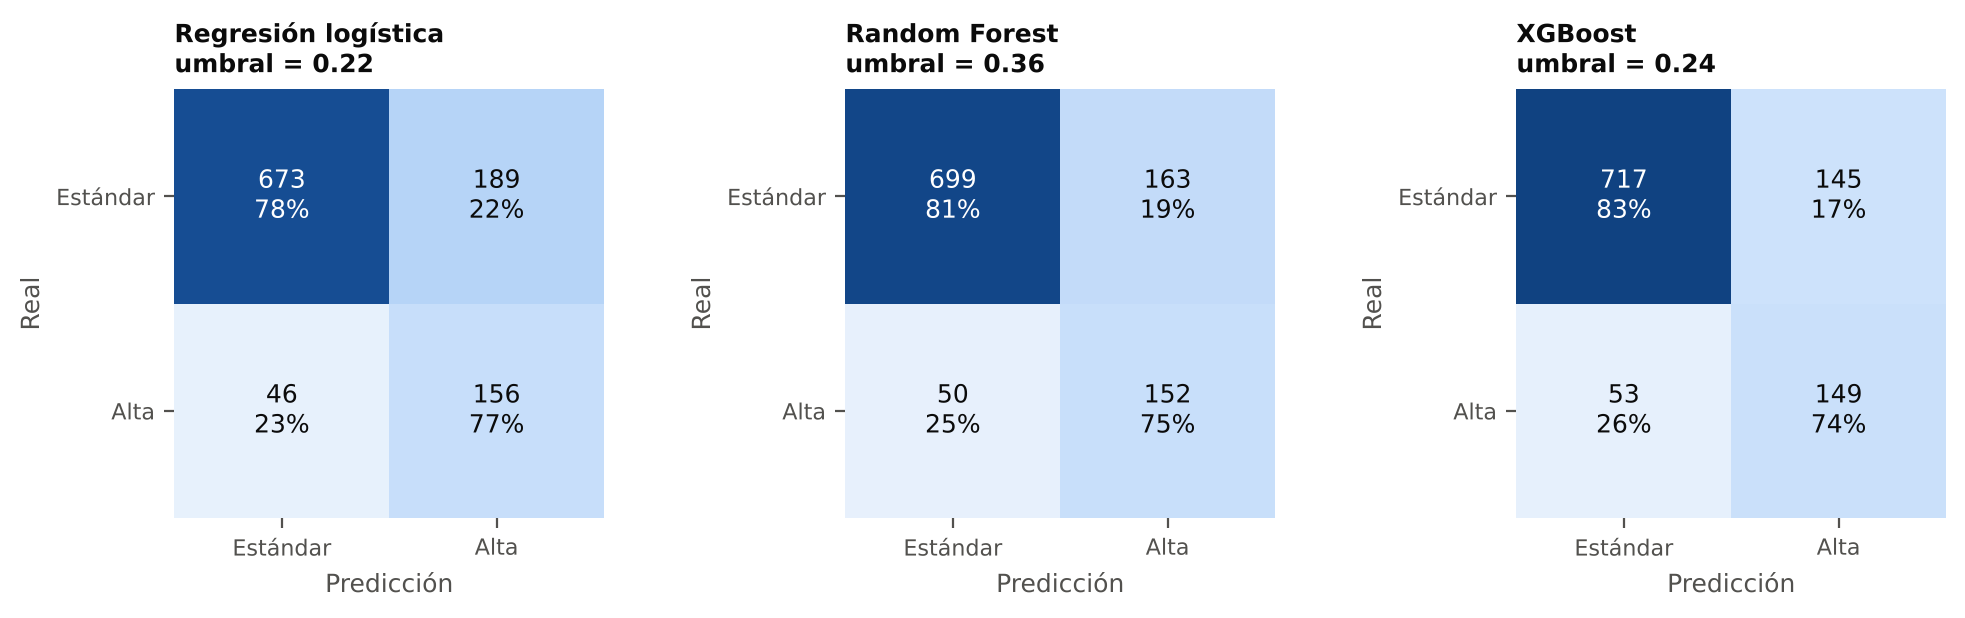

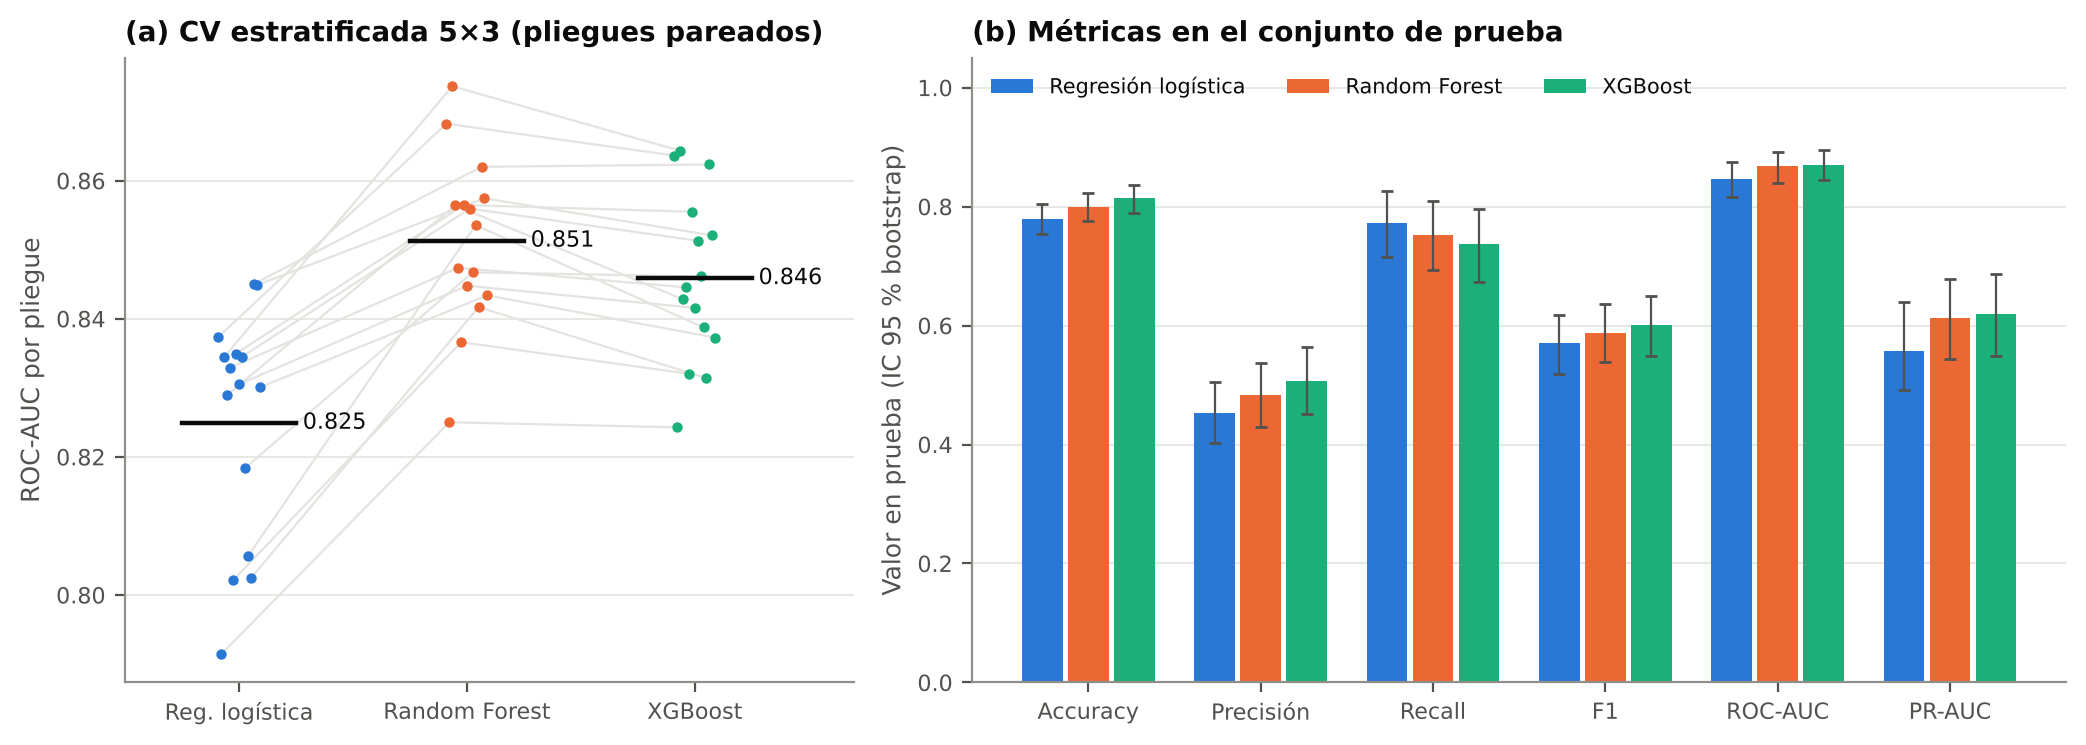

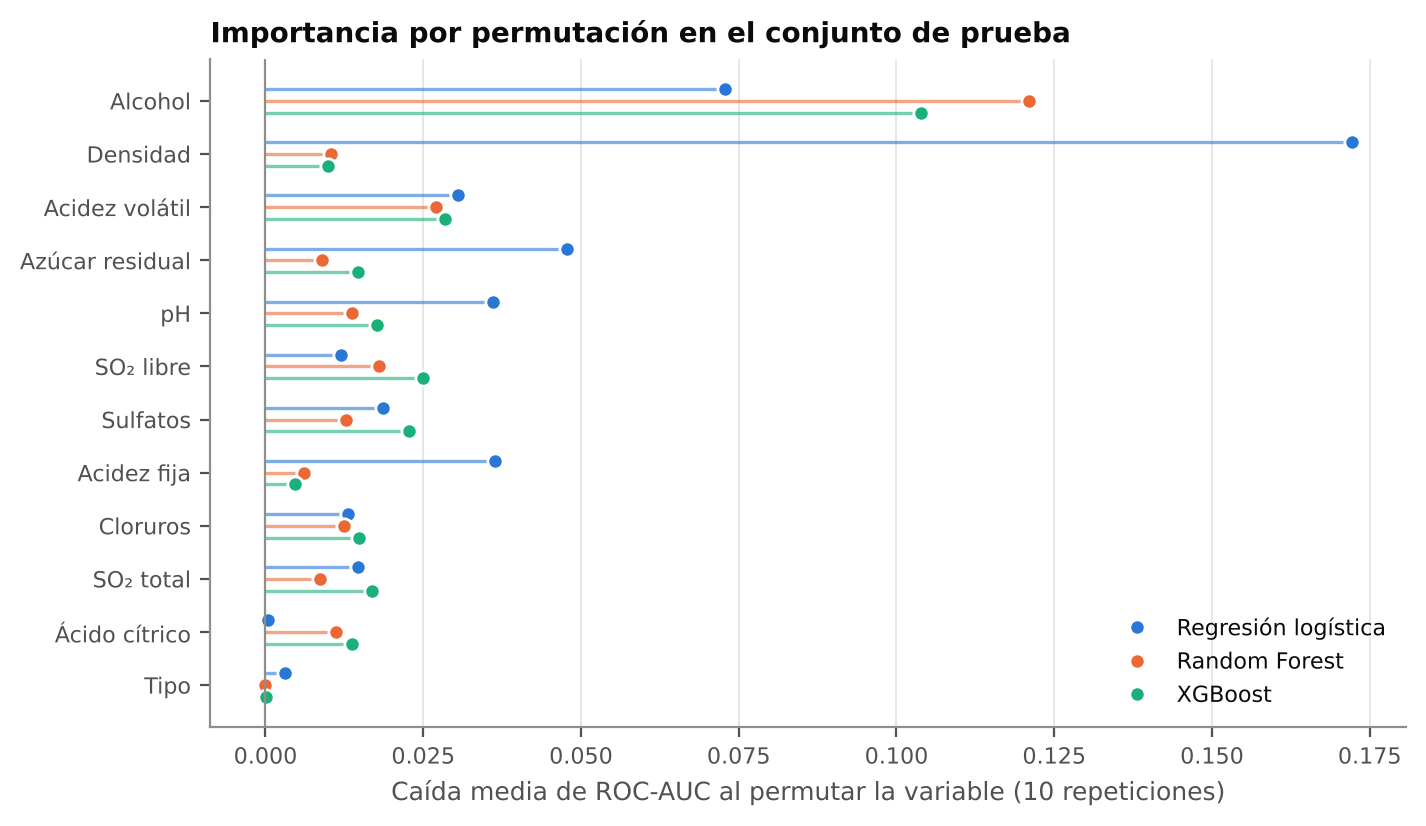

In [9]:
for f in comp["figuras"]:
    display(Image(filename=str(f), width=900))

## 6. Trazabilidad en MLflow: consulta de runs y recarga del modelo registrado

In [10]:
from mlflow.tracking import MlflowClient
exp = mlflow.get_experiment_by_name(train.EXPERIMENTO)
runs = mlflow.search_runs([exp.experiment_id])
padres = runs[runs["tags.rol"].isin(["linea_base", "modelo_padre", "comparacion"])]
cols = ["tags.mlflow.runName", "params.algoritmo", "metrics.cv_roc_auc_media", "metrics.test_roc_auc", "metrics.test_f1",
        "params.umbral_decision", "tags.dataset_version", "tags.dataset_sha256"]
display(padres[cols].sort_values("tags.mlflow.runName").reset_index(drop=True))
print(f"Runs totales: {len(runs)} · combinaciones de grid registradas como runs hijos: {(runs['tags.rol'] == 'combinacion_grid').sum()}")

cliente = MlflowClient()
mv = cliente.get_model_version_by_alias(train.MODELO_REGISTRADO, "champion")
print(f"\nModelo registrado: {train.MODELO_REGISTRADO} v{mv.version} (alias 'champion') · run de origen {mv.run_id}")
print("Etiquetas de la versión:", {k: v for k, v in mv.tags.items()})

,tags.mlflow.runName,params.algoritmo,metrics.cv_roc_auc_media,metrics.test_roc_auc,metrics.test_f1,params.umbral_decision,tags.dataset_version,tags.dataset_sha256
0,00_linea_base_dummy,DummyClassifier,0.5000,0.5000,0.0000,0.5,1.1.0,c40859031f721635fe8eb99ef2f48652b2fb46d7591f17...
1,01_logreg_gridsearch,LogisticRegression,0.8250,0.8462,0.5704,0.2204,1.1.0,c40859031f721635fe8eb99ef2f48652b2fb46d7591f17...
2,02_rf_gridsearch,RandomForestClassifier,0.8541,0.8676,0.5880,0.3597,1.1.0,c40859031f721635fe8eb99ef2f48652b2fb46d7591f17...
3,03_xgb_gridsearch,XGBClassifier,0.8479,0.8706,0.6008,0.2445,1.1.0,c40859031f721635fe8eb99ef2f48652b2fb46d7591f17...
4,04_comparacion_estadistica,NaN,NaN,NaN,NaN,NaN,1.1.0,c40859031f721635fe8eb99ef2f48652b2fb46d7591f17...


Runs totales: 109 · combinaciones de grid registradas como runs hijos: 104

Modelo registrado: wine_calidad_alta_clf v1 (alias 'champion') · run de origen 8997ad556bb541e5a1a19bd662c86e05
Etiquetas de la versión: {'cv_roc_auc': '0.8541', 'test_roc_auc': '0.8676', 'test_f1': '0.5880', 'umbral_decision': '0.3597', 'dataset_version': '1.1.0', 'run_id': '8997ad556bb541e5a1a19bd662c86e05'}


In [11]:
# Recarga del campeón desde el Model Registry y predicción sobre 5 vinos de prueba
_, X_tr, X_te, y_tr, y_te = salida["datos"]
campeon = mlflow.sklearn.load_model(f"models:/{train.MODELO_REGISTRADO}@champion")
umbral = float(mv.tags["umbral_decision"])
muestra = X_te.head(5).copy()
muestra["prob_calidad_alta"] = campeon.predict_proba(X_te.head(5))[:, 1].round(3)
muestra["prediccion"] = (muestra["prob_calidad_alta"] >= umbral).astype(int)
muestra["real"] = y_te.head(5).values
display(muestra[["tipo", "alcohol", "acidez_volatil", "densidad", "prob_calidad_alta", "prediccion", "real"]])

,tipo,alcohol,acidez_volatil,densidad,prob_calidad_alta,prediccion,real
5076,blanco,9.8,0.34,0.9944,0.029,0,0
815,tinto,11.3,0.36,0.9957,0.341,0,0
1968,blanco,12.4,0.33,0.9903,0.612,1,1
1048,tinto,11.8,0.18,0.9947,0.587,1,0
2703,blanco,9.4,0.29,0.9938,0.041,0,0


**Abrir el panel de MLflow**

* **Local:** desde la raíz del repositorio ejecutar `mlflow ui --backend-store-uri sqlite:///mlflow.db` y abrir <http://127.0.0.1:5000>.
* **Colab:** descargar `mlflow.db` y la carpeta `mlruns/` y abrirlos localmente con el mismo comando (o exponer el puerto 5000 con un túnel como *ngrok*).

## 7. Conclusiones

1. **Calidad de datos.** El hallazgo principal de la limpieza fue el volumen de duplicados exactos: 1,177 registros (18 %). Sin eliminarlos, el mismo vino caería en entrenamiento y validación y las métricas saldrían infladas. Las reglas de validez no encontraron registros imposibles; la regla regulatoria marcó 63 vinos con SO₂ por encima del límite de la UE, de los cuales solo 3 son de calidad alta.
2. **Modelos.** Los dos ensambles de árboles superan con claridad a la regresión logística: +0.021 a +0.026 de ROC-AUC en los 15 pliegues de la CV repetida (t corregida de Nadeau-Bengio con Holm, p < 0.003). Entre **Random Forest** y **XGBoost** no hay diferencia significativa: RF gana 14 de 15 pliegues en CV, pero la t corregida da p = 0.059, y en prueba XGBoost queda 0.003 arriba con un IC 95 % de la diferencia que incluye el cero (McNemar p = 0.07).
3. **Campeón.** Siguiendo el criterio definido *antes* de ver la prueba (mayor ROC-AUC de validación cruzada), se registra **Random Forest** (`max_depth=20`, `min_samples_leaf=3`, `max_features="sqrt"`, `class_weight="balanced_subsample"`) como `wine_calidad_alta_clf@champion`. En prueba: ROC-AUC 0.868, PR-AUC 0.612, recall 0.75, precisión 0.48 y F1 0.59 con umbral 0.36. La línea base (siempre "estándar") logra 81 % de *accuracy* y F1 = 0: por eso la *accuracy* no se usa para decidir.
4. **Interpretación.** El alcohol es la variable más importante en los tres modelos. La regresión logística se apoya mucho en la densidad y el azúcar residual porque la densidad es casi una combinación lineal de alcohol y azúcar: es el efecto de la colinealidad detectada en el EDA.
5. **Rigor estadístico.** Wilcoxon sobre pliegues de CV declara significativa la diferencia RF vs. XGBoost (p = 0.0002), pero los pliegues comparten datos y no son independientes; la t corregida, que sí lo considera, no la declara significativa. Se reporta la conclusión conservadora.
6. **Deuda técnica a atender (enfoque MLOps).** Brecha entrenamiento–CV de ≈ 0.14 de ROC-AUC en los ensambles (memorizan el entrenamiento), umbral calibrado una sola vez, datos versionados en Git en lugar de DVC, seguimiento local en SQLite y ausencia de pruebas automáticas y de monitoreo de *drift*. El detalle y las acciones propuestas están en el reporte técnico y en `CHANGELOG.md`.